# Pooled edge accuracy (results 1.2)

Both validation sites (Muriwai and Pakiri) pooled, every scenario, Sentinel-2 and Landsat 8 kept separate.

**Table:** for each satellite and scenario, the images, coverage (transects with an edge, % of those possible), median distance, MedAE, RMSE, 90th percentile of |error| and % within sub-pixel (10 m Sentinel-2, 15 m Landsat 8). Saved as CSV and LaTeX; shown below.

**Figure:** violins of the transect distances for every scenario, **(a)** Sentinel-2 and **(b)** Landsat 8, in the style of the site figures (white solid line = median, dashed = 25th and 75th percentiles, grey bands = ±10 m, and on Landsat 8 also its ±15 m pixel (lighter); η<sub>dist</sub> = median distance; MedAE / RMSE on the right). Also saved as one figure per platform.

Reads `errors_all.csv` and `transects_per_line.csv` from `Data/NZCCD_comparison_batch` (the ±150 m BatchS comparison); uses only images every scenario has. Transects are pooled, so the site with more transects (Muriwai, about 400 per line against about 245 at Pakiri) weighs more. Everything is written to `Data/Extra_analyses/Pooled` (overwritten each run).

Run the settings cell, the functions cell, then the table and figure cells.

In [9]:
# ---------------- Settings ----------------
import os
DATA = os.path.join(os.getcwd(), 'Data')                        # run from the COASTGUARD-master folder
COMP_DIR = os.path.join(DATA, 'NZCCD_comparison_batch')         # errors_all.csv and transects_per_line.csv
OUT_DIR = os.path.join(DATA, 'Extra_analyses', 'Pooled')        # table and figures; overwritten on every run
SITES = ['Muriwai', 'Pakiri']                                   # pooled together

# Scenarios, top to bottom (rows of the table and violins); delete one to leave it out
SCENARIOS = ['default_WP', 'default_local', 'NZ_WP', 'NZ_local', 'NZsparse_WP', 'NZsparse_local']

WITHIN = 10          # m, accuracy target: grey band in the violins (Landsat 8 also shows its 15 m pixel)
PIXEL = {'S2': 10, 'L8': 15}   # m, pixel sizes: the table's '% within sub-pixel' uses each satellite's own
XLIM = 150           # m either side of NZCCD (the transect half-length, so every error is shown)
FIG_WIDTH = 7.5      # inches, both panels side by side; scale to the text width when inserting
PANEL_HEIGHT = 4.6   # inches
LINE_WIDTH = 1.4     # panel borders and axis ticks
DPI = 300


In [10]:
# ---------------- Functions (run once; nothing to edit here) ----------------
import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib import cbook, mlab
from IPython.display import display

SCEN_RUN = {'default_WP': 'Default (WP)', 'default_local': 'Default (local)', 'NZ_WP': 'NZ (WP)',
            'NZ_local': 'NZ (local)', 'NZsparse_WP': 'NZsparse (WP)', 'NZsparse_local': 'NZsparse (local)'}  # as in errors_all.csv
SCEN_SHORT = {'default_WP': 'VedgeSat WP', 'default_local': 'VedgeSat local', 'NZ_WP': 'NZ WP',
              'NZ_local': 'NZ local', 'NZsparse_WP': 'NZsparse WP', 'NZsparse_local': 'NZsparse local'}
SCEN_TABLE = {'default_WP': 'VedgeSat, Weighted Peaks', 'default_local': 'VedgeSat, local threshold',
              'NZ_WP': 'NZ, Weighted Peaks', 'NZ_local': 'NZ, local threshold',
              'NZsparse_WP': 'NZsparse, Weighted Peaks', 'NZsparse_local': 'NZsparse, local threshold'}
SCEN_COLOUR = {'default_WP': '#1a0b2e', 'default_local': '#1b068d',     # same colours as the site figures
               'NZ_WP': '#1560bd', 'NZ_local': '#8f99fb',
               'NZsparse_WP': '#cc5500', 'NZsparse_local': '#fca636'}
SAT_NAME = {'S2': 'Sentinel-2', 'L8': 'Landsat 8'}
ETA = r'$\eta_{dist}$'
signed = lambda v: f'{v:+.1f}'.replace('-', '−')


def load_errors():
    """errors_all.csv for SITES and SCENARIOS, keeping only images every scenario has (per site and satellite)."""
    E = pd.read_csv(os.path.join(COMP_DIR, 'errors_all.csv'))
    E = E[E.site.isin(SITES) & E.run.isin([SCEN_RUN[k] for k in SCENARIOS])].copy()
    E['date'] = E['date'].astype(str).str[:10]
    E['nzccd_date'] = E['nzccd_date'].astype(str).str[:10]
    E['img'] = E.nzccd_date + '|' + E.date
    keep = []
    for (site, sat), g in E.groupby(['site', 'satname']):
        shared = set.intersection(*[set(gg.img) for _, gg in g.groupby('run')])
        dropped = sorted(set(g.img) - shared)
        if dropped:
            print(f'{site} {sat}: images not in every scenario, left out: {dropped}')
        keep.append(g[g.img.isin(shared)])
    return pd.concat(keep)


def pooled_table(E):
    """Both sites pooled (transects pooled, so the site with more transects weighs more)."""
    T = pd.read_csv(os.path.join(COMP_DIR, 'transects_per_line.csv'))
    T['nzccd_date'] = T['nzccd_date'].astype(str).str[:10]
    n_tr = T.set_index(['site', 'nzccd_date']).transects
    rows = []
    for sat in ['S2', 'L8']:
        d = E[E.satname == sat]
        imgs = d[['site', 'nzccd_date', 'img']].drop_duplicates()
        possible = sum(n_tr.get((r.site, r.nzccd_date), np.nan) for r in imgs.itertuples())
        for k in SCENARIOS:
            e = d[d.run == SCEN_RUN[k]].error_m.values
            if not len(e):
                continue
            rows.append({'satellite': sat, 'scenario': k, 'images': len(imgs),
                         'images_by_site': ' + '.join(f'{s} {n}' for s, n in imgs.groupby('site').size().items()),
                         'transects': len(e), 'coverage_pct': 100 * len(e) / possible,
                         'median_m': np.median(e), 'MedAE_m': np.median(np.abs(e)),
                         'RMSE_m': np.sqrt(np.mean(e ** 2)), 'p90_abs_m': np.percentile(np.abs(e), 90),
                         'pixel_m': PIXEL[sat], 'within_pixel_pct': 100 * np.mean(np.abs(e) <= PIXEL[sat])})
    return pd.DataFrame(rows)


def write_latex(P, path):
    cols = [('coverage_pct', 'Coverage (\\%)', '{:.1f}'), ('median_m', 'Median distance', '{:+.1f}'),
            ('MedAE_m', 'MedAE', '{:.1f}'), ('RMSE_m', 'RMSE', '{:.1f}'), ('p90_abs_m', 'P90 $|$error$|$', '{:.1f}'),
            ('within_pixel_pct', 'Within sub-pixel (\\%)', '{:.1f}')]
    L = [r'\begin{tabular}{ll' + 'r' * len(cols) + '}', r'\toprule',
         'Satellite & Scenario & ' + ' & '.join(c[1] for c in cols) + r' \\', r'\midrule']
    for i, sat in enumerate(['S2', 'L8']):
        sub = P[P.satellite == sat]
        if sub.empty:
            continue
        if i and L[-1] != r'\midrule':
            L.append(r'\midrule')
        for j, r in enumerate(sub.itertuples()):
            first = (rf'\multirow{{{len(sub)}}}{{*}}{{\shortstack[l]{{{SAT_NAME[sat]}\\({r.images} images)}}}}' if j == 0 else '')
            vals = [f.format(getattr(r, c)).replace('-', '$-$') for c, _, f in cols]
            L.append(f'{first} & {SCEN_TABLE[r.scenario]} & ' + ' & '.join(vals) + r' \\')
    L += [r'\midrule', rf'\multicolumn{{{len(cols) + 2}}}{{l}}{{\footnotesize\emph{{Distances in metres; median distance + seaward, $-$ landward of NZCCD; sub-pixel: within {PIXEL["S2"]} m (Sentinel-2), {PIXEL["L8"]} m (Landsat 8).}}}} \\',
          r'\bottomrule', r'\end{tabular}']
    open(path, 'w', encoding='utf-8').write('\n'.join(L) + '\n')


# ---------- violins (as in the site figures) ----------
def violin_panel(ax, E, sat, letter, xl):
    d = E[E.satname == sat]
    width, tail = 0.56, 0.008
    y0, y1 = len(SCENARIOS) - 0.35, -1.45                      # y limits (inverted: first scenario at the top)
    top = (y0 + 0.75) / (y0 - y1)                              # band and zero line stop under the heading
    bands = sorted({WITHIN, PIXEL.get(sat, WITHIN)}, reverse=True)    # Landsat 8: its 15 m pixel, lighter, around 10 m
    for b, c in zip(bands, ['#ececec', '#dcdcdc'][-len(bands):] if len(bands) > 1 else ['#e3e3e3']):
        ax.axvspan(-b, b, ymax=top, color=c, zorder=0, lw=0)
    ax.axvline(0, ymax=top, color='#7a7a7a', lw=0.8, zorder=1)
    yax = ax.get_yaxis_transform()
    for i, k in enumerate(SCENARIOS):
        e = d[d.run == SCEN_RUN[k]].error_m.values
        name = ax.text(0.03, i - 0.31, SCEN_SHORT[k], transform=yax, fontsize=7, ha='left', va='bottom', zorder=5)
        if not len(e):
            continue
        ax.annotate(f'{ETA} = {signed(np.median(e))} m', xy=(1, 0), xycoords=name, xytext=(7, 0),
                    textcoords='offset points', fontsize=7, ha='left', va='bottom', zorder=5)
        ax.text(0.97, i - 0.31, f'{np.median(np.abs(e)):.1f} / {np.sqrt(np.mean(e ** 2)):.1f}', transform=yax,
                fontsize=7, ha='right', va='bottom', zorder=5)
        if len(e) < 2 or np.std(e) == 0:
            continue
        st = cbook.violin_stats(np.clip(e, -xl, xl), lambda X, c: mlab.GaussianKDE(X, 'scott').evaluate(c),
                                points=400)[0]
        xs, half = st['coords'], np.maximum(0.5 * width * st['vals'] / st['vals'].max(), tail)
        ax.fill_between(xs, i + 0.05 - half, i + 0.05 + half, facecolor=SCEN_COLOUR[k], edgecolor='none', zorder=2)
        for q, ls, lw in [(25, (0, (2, 1.2)), 0.9), (50, '-', 1.4), (75, (0, (2, 1.2)), 0.9)]:
            xq = np.percentile(e, q)
            if -xl < xq < xl:
                h = np.interp(xq, xs, half)
                ax.plot([xq, xq], [i + 0.05 - h, i + 0.05 + h], color='white', lw=lw, ls=ls, zorder=3,
                        solid_capstyle='butt')
    n = d.groupby('site').img.nunique()
    ax.text(0.13, 0.985, f"{SAT_NAME[sat]}, both sites: {d.img.nunique()} images", transform=ax.transAxes,
            fontsize=8.5, ha='left', va='top', zorder=6)
    ax.text(0.13, 0.935, ' + '.join(f'{s} {v}' for s, v in n.items()), transform=ax.transAxes, fontsize=6.5,
            color='#555', ha='left', va='top', zorder=6)
    ax.text(0.97, 0.935, 'MedAE / RMSE (m)', transform=ax.transAxes, fontsize=6.5, color='#444', ha='right',
            va='top', zorder=6)
    ax.set_yticks([])
    ax.set_ylim(y0, y1)
    ax.set_xlim(-xl, xl)
    step = 50 if xl > 60 else 20
    ticks = np.arange(-(xl // step) * step, xl + 1e-9, step)
    ax.set_xticks(ticks)
    ax.set_xticklabels([f'{t:g}'.replace('-', '−') for t in ticks], fontsize=7)
    ax.tick_params(axis='x', direction='out', length=4, width=LINE_WIDTH, pad=2)
    labs = ax.get_xticklabels()                      # end labels kept inside the panel's width
    if len(labs) > 1 and abs(ticks[0]) >= xl:
        labs[0].set_ha('left'); labs[-1].set_ha('right')
    for sp in ax.spines.values():
        sp.set_linewidth(LINE_WIDTH)
    lab = ax.set_xlabel('Distance$_{satellite - NZCCD}$ (m)', fontsize=8, labelpad=2)
    for x, t, c, ha in [(0, 'land', '#b39b62', 'left'), (1, 'sea', '#2d6a9f', 'right')]:
        ax.annotate(t, xy=(x, 0.5), xycoords=('axes fraction', lab), color=c, fontsize=8, ha=ha, va='center')
    if letter:
        ax.text(0.025, 0.985, f'({letter})', transform=ax.transAxes, ha='left', va='top', fontsize=10, zorder=12,
                bbox=dict(fc='white', ec='black', lw=LINE_WIDTH * 0.75, boxstyle='square,pad=0.25'))


def save(fig, name):
    os.makedirs(OUT_DIR, exist_ok=True)
    png = os.path.join(OUT_DIR, name + '.png')
    fig.savefig(png, dpi=DPI, bbox_inches='tight')
    fig.savefig(png.replace('.png', '.pdf'), bbox_inches='tight')
    print('Saved', png, '(and .pdf)')
    display(fig)
    plt.close(fig)


def pooled_figures(E):
    sats = [s for s in ['S2', 'L8'] if (E.satname == s).any()]
    # both platforms side by side, (a) and (b)
    fig, axes = plt.subplots(1, len(sats), figsize=(FIG_WIDTH, PANEL_HEIGHT), gridspec_kw=dict(wspace=0.06))
    for ax, sat, letter in zip(np.atleast_1d(axes), sats, 'ab'):
        violin_panel(ax, E, sat, letter, XLIM)
    save(fig, 'pooled_violins')
    # and each platform on its own
    for sat in sats:
        fig, ax = plt.subplots(figsize=(FIG_WIDTH / 2, PANEL_HEIGHT))
        violin_panel(ax, E, sat, None, XLIM)
        save(fig, f'pooled_violins_{sat}')


## Table

In [11]:
# ---------------- Table: both sites pooled ----------------
E = load_errors()
P = pooled_table(E)
os.makedirs(OUT_DIR, exist_ok=True)
csv = os.path.join(OUT_DIR, 'pooled_metrics.csv')
P.round(1).to_csv(csv, index=False)
write_latex(P, csv.replace('.csv', '.tex'))
print('Saved', csv, 'and', os.path.basename(csv.replace('.csv', '.tex')))
show = P.assign(Satellite=P.satellite.map(SAT_NAME), Scenario=P.scenario.map(SCEN_TABLE)).set_index(['Satellite', 'Scenario'])
display(show[['images', 'transects', 'coverage_pct', 'median_m', 'MedAE_m', 'RMSE_m', 'p90_abs_m', 'within_pixel_pct']].round(1))
print('Images per site:', P.groupby('satellite').images_by_site.first().to_dict())

Saved /Users/benmclean/Library/CloudStorage/OneDrive-TheUniversityofAuckland/Postgrad Papers/Project/COASTGUARD/COASTGUARD-master/Data/Extra_analyses/Pooled/pooled_metrics.csv and pooled_metrics.tex


images  transects  coverage_pct  \
Satellite  Scenario                                                     
Sentinel-2 VedgeSat, Weighted Peaks       14       4291          98.1   
           VedgeSat, local threshold      14       4336          99.1   
           NZ, Weighted Peaks             14       4373         100.0   
           NZ, local threshold            14       4374         100.0   
           NZsparse, Weighted Peaks       14       4373         100.0   
           NZsparse, local threshold      14       4372          99.9   
Landsat 8  VedgeSat, Weighted Peaks       13       3887          87.4   
           VedgeSat, local threshold      13       4128          92.9   
           NZ, Weighted Peaks             13       4431          99.7   
           NZ, local threshold            13       4443         100.0   
           NZsparse, Weighted Peaks       13       4430          99.7   
           NZsparse, local threshold      13       4438          99.8   

                                      median_m  MedAE_m  RMSE_m  p90_abs_m  \
Satellite  Scenario                                                          
Sentinel-2 VedgeSat, Weighted Peaks        2.9      6.4    28.3       43.9   
           VedgeSat, local threshold     -16.5     16.8    33.2       53.4   
           NZ, Weighted Peaks              3.9      5.1     9.8       16.2   
           NZ, local threshold            -5.2      5.4    16.0       20.2   
           NZsparse, Weighted Peaks        3.9      5.1     9.8       16.2   
           NZsparse, local threshold       7.5      7.6     9.3       13.1   
Landsat 8  VedgeSat, Weighted Peaks      -22.6     25.5    47.1       84.6   
           VedgeSat, local threshold     -26.5     26.9    42.3       71.1   
           NZ, Weighted Peaks             21.5     21.7    33.0       53.8   
           NZ, local threshold             2.4      9.0    14.4       19.9   
           NZsparse, Weighted Peaks       21.5     21.6    33.9       55.7   
           NZsparse, local threshold      19.1     19.2    24.2       35.5   

                                      within_pixel_pct  
Satellite  Scenario                                     
Sentinel-2 VedgeSat, Weighted Peaks               66.5  
           VedgeSat, local threshold              24.8  
           NZ, Weighted Peaks                     81.7  
           NZ, local threshold                    69.4  
           NZsparse, Weighted Peaks               81.9  
           NZsparse, local threshold              68.3  
Landsat 8  VedgeSat, Weighted Peaks               32.8  
           VedgeSat, local threshold              23.0  
           NZ, Weighted Peaks                     34.6  
           NZ, local threshold                    76.5  
           NZsparse, Weighted Peaks               34.7  
           NZsparse, local threshold              38.2

Images per site: {'L8': 'Muriwai 8 + Pakiri 5', 'S2': 'Muriwai 6 + Pakiri 8'}


## Figure

Saved /Users/benmclean/Library/CloudStorage/OneDrive-TheUniversityofAuckland/Postgrad Papers/Project/COASTGUARD/COASTGUARD-master/Data/Extra_analyses/Pooled/pooled_violins.png (and .pdf)


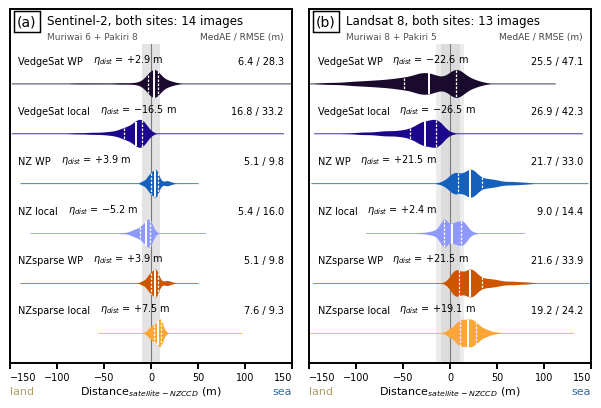

Saved /Users/benmclean/Library/CloudStorage/OneDrive-TheUniversityofAuckland/Postgrad Papers/Project/COASTGUARD/COASTGUARD-master/Data/Extra_analyses/Pooled/pooled_violins_S2.png (and .pdf)


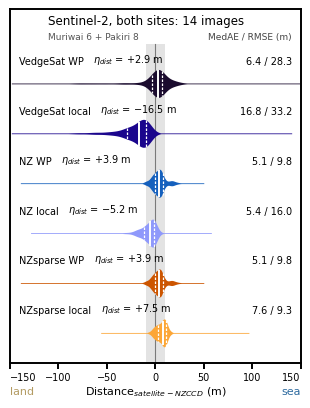

Saved /Users/benmclean/Library/CloudStorage/OneDrive-TheUniversityofAuckland/Postgrad Papers/Project/COASTGUARD/COASTGUARD-master/Data/Extra_analyses/Pooled/pooled_violins_L8.png (and .pdf)


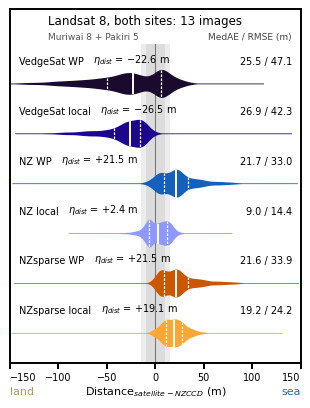

In [12]:
# ---------------- Figure: pooled violins, Sentinel-2 (a) and Landsat 8 (b) ----------------
pooled_figures(load_errors())